In [1]:
import numpy as np
import pandas as pd
from scipy.stats import zscore
from matplotlib import pyplot as plt
import datetime

# Análisis de componentes principales

* El análisis de componentes principales es súmamente útil al momento de realizar análisis estadístico sobre datos con dimensiones altas (muchas columnas)
* En la actualidad, este análisis es utilizado principalmente para la compresión de imágenes en el campo de aprendizaje automático, con el fin de que los modelos de detección de imágenes utilicen menos información como insumo y su calibración sea más eficiente.
* En el campo de las finanzas, este análisis es ampliamente utilizado en el campo de las curvas de tasas de interés, ya que éstas representan un conjunto de datos altamente correlacionados de altas dimensiones

* Antes de continuar con este modelo, es importante mencionar que para su buen funcionamiento, es importante "Estandarizar los datos"

$$X^{stand} = \frac{X- \mu}{\sigma}$$

In [38]:
df_curves = pd.read_csv('curvas.csv',index_col=0)
df_curves.index = [datetime.datetime(1899, 12, 30) + datetime.timedelta(days=date_num) 
                   for date_num in df_curves.index]
df_curves = df_curves.iloc[400:,:6]
df_curves = df_curves.iloc[400:,:6]
means = np.mean(df_curves, axis=0).values
stds = np.std(df_curves, axis=0).values
stds = np.array(1)
df_curvesdiff = (df_curves-means)/stds
corr_matrix_array = df_curvesdiff.corr()

Podemos observar que los datos correspondientes a las tasas de interés de este conjunto de datos están altamente correlacionados.

<Figure size 432x288 with 0 Axes>

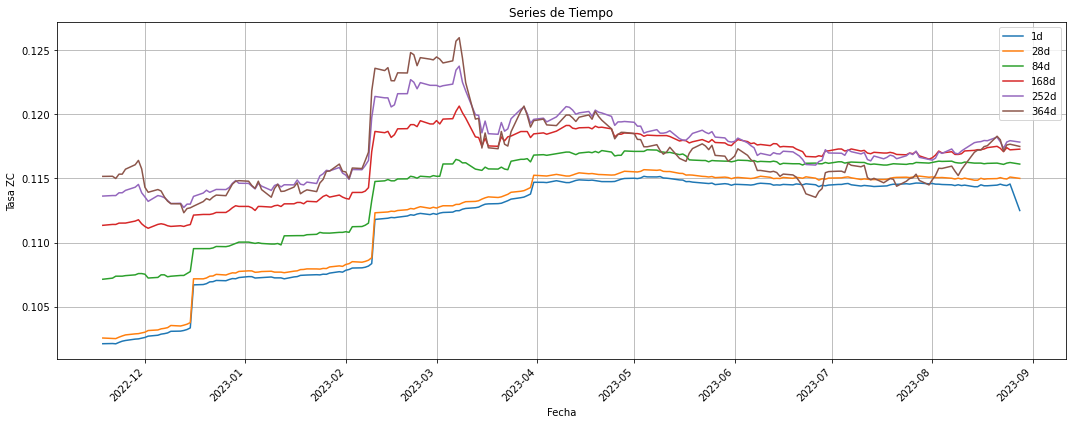

In [39]:
plt.figure();
df_curves.plot(figsize=(15, 6));
plt.xlabel('Fecha');
plt.ylabel('Tasa ZC');
plt.title('Series de Tiempo');
plt.legend();
plt.grid(True);
plt.xticks(rotation=45);
plt.tight_layout();
plt.show();

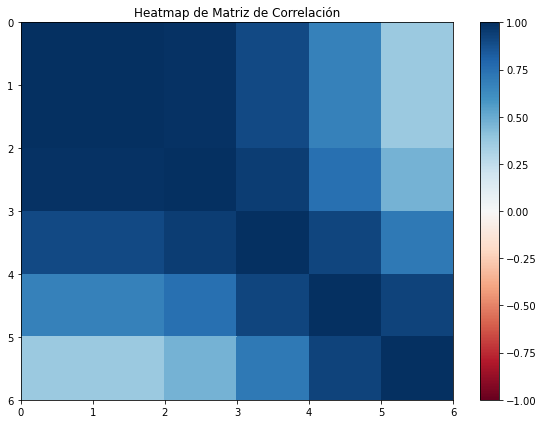

In [40]:
plt.figure(figsize=(8, 6))
heatmap = plt.pcolor(corr_matrix_array, cmap='RdBu', vmin=-1, vmax=1)
plt.colorbar(heatmap)
plt.title('Heatmap de Matriz de Correlación')
#plt.xticks(np.arange(0.5, num_features + 0.5), corr_matrix_array.columns, rotation=45)
#plt.yticks(np.arange(0.5, num_features + 0.5), corr_matrix_array.columns)
plt.gca().invert_yaxis()  # Invertir los ejes y para que la disposición sea similar a la matriz
plt.tight_layout()
plt.show()

El principio matemático principal detrás del análisis de componentes principales es  el Teorema de descomposición espectral, el cual  afirma que para cualquier matriz real simétrica $n x n$ $Q$ puede ser escrita como
$$ Q= ALA^{T}$$

Donde:

* $L = diag(\lambda_1,\lambda_2,...,\lambda_n)$ es la matriz diagonal de eigenvectores de $Q$ con $\lambda_1 \geq \lambda_2 \geq ... \geq \lambda_n$
* $A$ es la matriz ortogonal ($A^{-1} = A^{T}$), cuyas columnas $a_1, a_2,...,a_n$ son los eigenvectores asociados a $Q$ ($Qa_i = \lambda_i a_i$), los cuales forman una base ortonormal en $\mathbb{R}^{n}$

* Consideremos un vector $X$ con media $\mu = \mathbb{E}\left[X\right]$ y una matriz de covarianza $Q=cov(X)$. La transformación de $X$  a través de las componentes principales está definida como:
$$Y= A^{T}(X-\mu),$$
* La cual puede interpretarse compo re-centrar y ritar el vector $X$. Notar que:
$$Y_i= a_i^{T}(X-\mu),$$
* De esta ecuación, podemos obtener la siguiente despomposición:
$$X= \mu + AY = \mu + \sum_{i=1}^{n}Y_ia_i$$
* Podemos notar que $\mathbb{E}\left[Y\right] = 0$  y $Cov(Y) = A^{T}QA = A^{T}ALA^{T}A = L$
* De aquí es facil ver que para reducir el espacio, podemos tomar $k \leq n$ tal que:
$$X \approx\mu + \sum_{i=1}^{k}Y_ia_i$$
* Donde $\frac{\sum_{i=1}^{k}\lambda_i}{\sum_{i=1}^{n}\lambda_i}$ representa el porcentaje de variabilidad explicado por las $k$ primeras componentes.

In [41]:
cov_matrix_array = np.cov(df_curvesdiff.T)
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix_array)#Vector de eigenvectores A y eigenbvalores lambda

In [42]:
df_eigval = pd.DataFrame({"Eigenvalores":eigenvalues})
#varianza explicada por cada componente
df_eigval["Proporción explicada (%)"] = (df_eigval["Eigenvalores"] / np.sum(df_eigval["Eigenvalores"])*100)


df_eigval

,Eigenvalores,Proporción explicada (%)
0,5.687119e-05,84.086579
1,1.055654e-05,15.608311
2,1.312723e-07,0.194092
3,4.524558e-08,0.066898
4,9.519693e-09,0.014075
5,2.032112e-08,0.030046


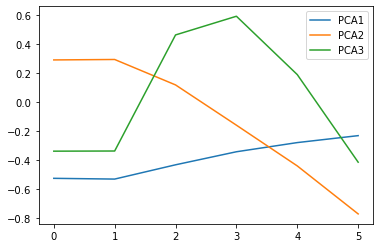

In [43]:
df_eigenvecs = pd.DataFrame(eigenvectors[:,:3],columns=['PCA1','PCA2','PCA3'])
df_eigenvecs.plot();

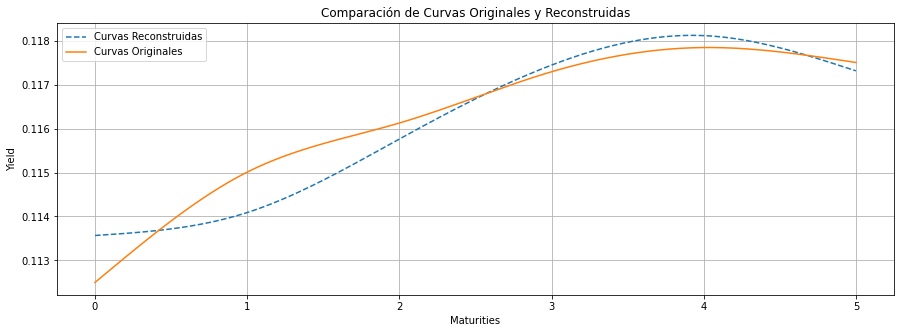

In [44]:
# Reducir dimensionalidad a 3 componentes principales
from scipy.interpolate import CubicSpline
num_components = 3
principal_components = eigenvectors[:, :num_components]
Y = np.dot(df_curvesdiff.values, principal_components)
# Reconstruir los datos
X_reconstructed = (np.dot(Y, principal_components.T)*stds)+means
curvas_reconstruidas = pd.DataFrame(X_reconstructed)
curvas_reconstruidas.index = df_curvesdiff.index
curvas_reconstruidas.columns = df_curvesdiff.columns



########Gráfico Bonito###########


# Definir maturities y puntos de interpolación
maturities = np.arange(len(df_curves.columns))
interp_maturities = np.linspace(0, len(df_curves.columns) - 1, 1000)  # Más puntos para interpolación suave

plt.figure(figsize=(15, 5))

# Realizar interpolación spline cúbica para curvas originales y reconstruidas
cs_original = CubicSpline(maturities, df_curves.iloc[-1,:], bc_type='natural')
cs_reconstruida = CubicSpline(maturities, curvas_reconstruidas.iloc[-1,:], bc_type='natural')

# Graficar las curvas interpoladas
plt.plot(interp_maturities, cs_reconstruida(interp_maturities), label='Curvas Reconstruidas', linestyle='dashed')
plt.plot(interp_maturities, cs_original(interp_maturities), label='Curvas Originales', linestyle='solid')

plt.xlabel('Maturities')
plt.ylabel('Yield')
plt.title('Comparación de Curvas Originales y Reconstruidas')
#plt.xticks(np.linspace(0, len(df_curves.columns) - 1, 10), curvas_reconstruidas.columns[::len(curvas_reconstruidas.columns)//10], rotation=45)
plt.legend()
plt.grid(True)
plt.show()



In [45]:
#Podemos ver que las condiciones de Y se cumplen

Y_ = pd.DataFrame(np.dot(df_curvesdiff.values, eigenvectors))
Y_.cov()

,0,1,2,3,4,5
0,5.687119e-05,1.567046e-21,-1.889272e-20,3.495988e-21,-1.660026e-22,-6.685779e-22
1,1.567046e-21,1.055654e-05,-4.352108e-21,6.044915e-21,2.509014e-21,-3.156282e-21
2,-1.889272e-20,-4.352108e-21,1.312723e-07,-7.185165e-21,2.485322e-21,-4.773229e-21
3,3.495988e-21,6.044915e-21,-7.185165e-21,4.524558e-08,7.604772e-21,-3.005954e-21
4,-1.660026e-22,2.509014e-21,2.485322e-21,7.604772e-21,9.519693e-09,1.685636e-20
5,-6.685779e-22,-3.156282e-21,-4.773229e-21,-3.005954e-21,1.685636e-20,2.032112e-08


In [46]:
int(len(df_curvesdiff.columns)/2)


3

In [47]:
len(df_curvesdiff.columns)
X_slope = df_curvesdiff.iloc[:,-1]-df_curvesdiff.iloc[:,0]
X_curv = df_curvesdiff.iloc[:,-1]+df_curvesdiff.iloc[:,0] - 2*df_curvesdiff.iloc[:,int(len(df_curvesdiff.columns)/2)]

np.corrcoef(X_curv,-Y_.iloc[:,2])

array([[1.        , 0.66827867],
       [0.66827867, 1.        ]])

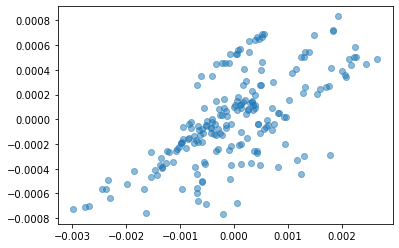

In [48]:
plt.scatter(X_curv, -Y_.iloc[:,2], alpha=0.5)

In [49]:
np.corrcoef(X_slope,-Y_.iloc[:,1])

array([[1.        , 0.84044864],
       [0.84044864, 1.        ]])

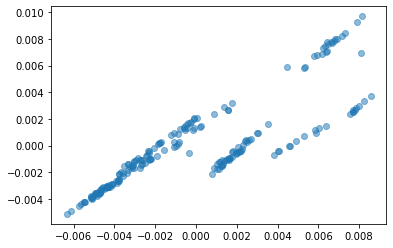

In [50]:
plt.scatter(X_slope, -Y_.iloc[:,1], alpha=0.5)

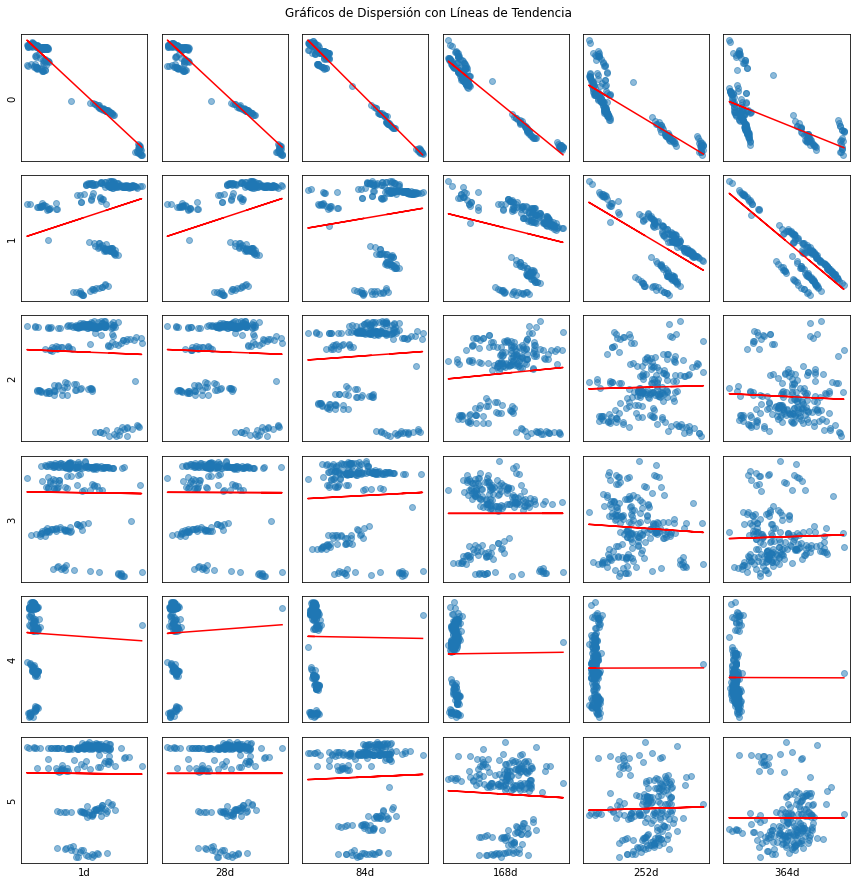

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Generar DataFrames de ejemplo
np.random.seed(0)
num_samples = 50
df1 = Y_
df2 = df_curves
num_features = len(df1.columns)


# Crear un gráfico de múltiples gráficos de dispersión
fig, axes = plt.subplots(len(df1.columns), len(df2.columns), figsize=(12, 12))

for i, column1 in enumerate(df1.columns):
    for j, column2 in enumerate(df2.columns):
        ax = axes[i, j]
        ax.scatter(df1[column1], df2[column2], alpha=0.5)
        
        # Agregar una línea de tendencia
        z = np.polyfit(df1[column1], df2[column2], 1)
        p = np.poly1d(z)
        ax.plot(df1[column1], p(df1[column1]), color='red')
        
        # Añadir etiquetas de ejes solo en los bordes izquierdo y abajo
        if i == num_features - 1:
            ax.set_xlabel(column2)
        if j == 0:
            ax.set_ylabel(column1)
        
        # No mostrar etiquetas en las otras posiciones
        ax.set_xticks([])
        ax.set_yticks([])
        
plt.tight_layout()
plt.suptitle('Gráficos de Dispersión con Líneas de Tendencia', y=1.02)
plt.show()
